# Why Did a 6.3% Drop in Egg Supply Triple the Price of Eggs?

**ECON 630 — Week 7**

Bird flu (HPAI) has been killing US egg-laying hens since February 2022. By January 2025 the
US flock was **6.3% smaller** than normal (USDA), yet the price of a dozen eggs **more than
tripled**. Why would such a small drop in supply cause such a big jump in price?

**Data used (nothing else):**

| File | Series |
|---|---|
| `APU0000708111.csv` | BLS Average Price: Eggs, Grade A, Large, per Dozen, US city average (monthly, nominal $) |
| `CPIAUCSL.csv` | BLS CPI-U, All Items, US city average, seasonally adjusted (1982-84 = 100) |
| `an-empirical-evaluation-of-egg-demand-in-the-united-states.pdf` | Bakhtavoryan, Hovhannisyan, Devadoss & Lopez (2021), *Journal of Agricultural and Applied Economics* 53(2) |


---
## Step 1 — Load all three files, merge, find the missing month, and deflate

1. Read the paper (held for Step 3).
2. Load both CSVs and merge them on `observation_date`.
3. Find the month missing from both, and explain why.
4. Convert the nominal egg price to August 2026 dollars:

$$\text{real price} = \text{price} \times \frac{\text{CPI}_{\text{Aug 2026}}}{\text{CPI}_t}$$


In [1]:
import pathlib

import pandas as pd
import pypdf

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

REPO = pathlib.Path.cwd()
EGG_CSV   = REPO / "APU0000708111.csv"
CPI_CSV   = REPO / "CPIAUCSL.csv"
PAPER_PDF = REPO / "an-empirical-evaluation-of-egg-demand-in-the-united-states.pdf"

for f in (EGG_CSV, CPI_CSV, PAPER_PDF):
    print(f"{'found  ' if f.exists() else 'MISSING'} {f.name}")

found   APU0000708111.csv
found   CPIAUCSL.csv
found   an-empirical-evaluation-of-egg-demand-in-the-united-states.pdf


### 1a. Read the paper

Extracted here so the full text is loaded alongside the data; Step 3 reads the elasticity out of it.

In [2]:
reader = pypdf.PdfReader(PAPER_PDF)
PAPER_TEXT = "\n".join(page.extract_text() or "" for page in reader.pages)
PAPER_LINES = [ln.strip() for ln in PAPER_TEXT.split("\n") if ln.strip()]

print(f"Read {PAPER_PDF.name}")
print(f"  pages      : {len(reader.pages)}")
print(f"  characters : {len(PAPER_TEXT):,}")
print("  title      : " + " ".join(PAPER_LINES[1:3]))
print("  authors    : " + PAPER_LINES[3])

Read an-empirical-evaluation-of-egg-demand-in-the-united-states.pdf
  pages      : 21
  characters : 76,459
  title      : An Empirical Evaluation of Egg Demand in the United States
  authors    : Rafael Bakhtavoryan 1 , Vardges Hovhannisyan 2* , Stephen Devadoss 3 and Jose Lopez 1


### 1b. Load both CSVs

Blank value cells are coerced to `NaN` so a missing month shows up as missing data rather than as text.

In [3]:
eggs = pd.read_csv(EGG_CSV, parse_dates=["observation_date"])
cpi  = pd.read_csv(CPI_CSV, parse_dates=["observation_date"])

eggs["APU0000708111"] = pd.to_numeric(eggs["APU0000708111"], errors="coerce")
cpi["CPIAUCSL"]       = pd.to_numeric(cpi["CPIAUCSL"],       errors="coerce")

for name, d, col in [("eggs", eggs, "APU0000708111"), ("CPI", cpi, "CPIAUCSL")]:
    print(f"{name:5s}: {len(d):4d} rows | "
          f"{d.observation_date.min():%Y-%m} to {d.observation_date.max():%Y-%m} | "
          f"{d[col].isna().sum()} blank value(s)")

eggs :  560 rows | 1980-01 to 2026-08 | 1 blank value(s)
CPI  :  956 rows | 1947-01 to 2026-08 | 1 blank value(s)


### 1c. Merge on `observation_date`

In [4]:
df = (eggs.merge(cpi, on="observation_date", how="inner")
          .rename(columns={"APU0000708111": "egg_price", "CPIAUCSL": "cpi"})
          .sort_values("observation_date")
          .reset_index(drop=True))

print(f"Merged: {len(df)} months, {df.observation_date.min():%Y-%m} to {df.observation_date.max():%Y-%m}")

# every calendar month in the range is present as a row -- nothing dropped by the merge
expected = pd.date_range(df.observation_date.min(), df.observation_date.max(), freq="MS")
print(f"Expected months in range: {len(expected)}  ->  gaps in the date index: "
      f"{len(expected.difference(df.observation_date))}")

Merged: 560 months, 1980-01 to 2026-08
Expected months in range: 560  ->  gaps in the date index: 0


### 1d. Which month is missing, and why?

In [5]:
missing = df[df[["egg_price", "cpi"]].isna().any(axis=1)]

print("Months with a missing value in either series:")
print(missing.to_string(index=False))
print()
for month in missing.observation_date:
    row = df.loc[df.observation_date == month].iloc[0]
    egg_ok = "present" if pd.notna(row.egg_price) else "MISSING"
    cpi_ok = "present" if pd.notna(row.cpi) else "MISSING"
    print(f"  {month:%B %Y}:  egg price = {egg_ok},  CPI = {cpi_ok}")

Months with a missing value in either series:
observation_date  egg_price  cpi
      2025-10-01        NaN  NaN

  October 2025:  egg price = MISSING,  CPI = MISSING


**The missing month is October 2025 — and it is missing from *both* series.**

The row exists in each file, but the value cell is empty in both
(`APU0000708111.csv` line 551 and `CPIAUCSL.csv` line 947 each read `2025-10-01,`).

**Why:** the federal government shutdown that began **October 1, 2025** suspended BLS
operations, and the October 2025 price collection never happened. No October 2025 CPI was
ever published. Both of these series are produced by the same BLS price-collection program
— CPI-U and the average-price series are built from the same monthly survey of retail
outlets — so when that collection stopped, both series got the same one-month hole.

This is a BLS-wide gap, not an egg-specific one: the same October 2025 blank appears in the
unrelated BLS rent series used for the Week 6 assignment in this repo.

The month is dropped rather than interpolated — no CPI exists for it, so no real price can
be computed for it.

In [6]:
n_before = len(df)
df = df.dropna(subset=["egg_price", "cpi"]).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} month(s) -> {len(df)} usable months")

Dropped 1 month(s) -> 559 usable months


### 1e. Deflate to August 2026 dollars

$$\text{real price}_t = \text{price}_t \times \frac{\text{CPI}_{\text{Aug 2026}}}{\text{CPI}_t}$$

August 2026 is the most recent month in both files. The base CPI is looked up from the data,
not typed in.

In [7]:
BASE_MONTH = pd.Timestamp("2026-08-01")
CPI_BASE   = df.loc[df.observation_date == BASE_MONTH, "cpi"].iloc[0]

df["real_price"] = df["egg_price"] * CPI_BASE / df["cpi"]

print(f"Base month : {BASE_MONTH:%B %Y}")
print(f"CPI(base)  : {CPI_BASE}")

# sanity check: deflating the base month itself must leave the price unchanged
base = df.loc[df.observation_date == BASE_MONTH].iloc[0]
assert abs(base.real_price - base.egg_price) < 1e-9
print(f"Check      : {BASE_MONTH:%b %Y} nominal ${base.egg_price:.3f} "
      f"-> real ${base.real_price:.3f}  (identical, as it must be)")

Base month : August 2026
CPI(base)  : 334.131
Check      : Aug 2026 nominal $2.272 -> real $2.272  (identical, as it must be)


In [8]:
print("First 3 months:")
print(df.head(3).to_string(index=False))
print("\nLast 3 months:")
print(df.tail(3).to_string(index=False))
print("\nAround the Feb 2022 bird flu outbreak:")
print(df[df.observation_date.between("2021-12-01", "2022-04-01")].to_string(index=False))

First 3 months:
observation_date  egg_price    cpi  real_price
      1980-01-01      0.879 78.000       3.765
      1980-02-01      0.774 79.000       3.274
      1980-03-01      0.812 80.100       3.387

Last 3 months:
observation_date  egg_price     cpi  real_price
      2026-06-01      2.141 332.568       2.151
      2026-07-01      2.189 332.813       2.198
      2026-08-01      2.272 334.131       2.272

Around the Feb 2022 bird flu outbreak:
observation_date  egg_price     cpi  real_price
      2021-12-01      1.788 280.845       2.127
      2022-01-01      1.929 282.543       2.281
      2022-02-01      2.005 284.500       2.355
      2022-03-01      2.046 287.674       2.376
      2022-04-01      2.520 288.561       2.918


**Step 1 summary**

- The paper was read: 21 pages, text extracted and held for Step 3.
- Merged on `observation_date`: **560 months**, January 1980 through August 2026.
- **October 2025 is missing from both series**, because the October 2025 federal government
  shutdown stopped BLS price collection that month. It is dropped, leaving **559 usable months**.
- Prices are now in **August 2026 dollars** using CPI(Aug 2026) = **334.131**, verified by the
  base-month identity check above.


---
## Step 2 — Plot the real egg price since 2000, and report three numbers

The chart runs from January 2000 to August 2026 with a vertical line at **February 2022**,
when bird flu first hit US egg-laying flocks.

Three numbers to report:

1. the average real price in **2020–2021** (the pre-outbreak baseline),
2. the **highest** real price and the month it occurred,
3. the **percent increase** from the first to the second.


In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

START    = pd.Timestamp("2000-01-01")
OUTBREAK = pd.Timestamp("2022-02-01")

plot_df = df[df.observation_date >= START].reset_index(drop=True)
print(f"Plot window: {len(plot_df)} months, "
      f"{plot_df.observation_date.min():%Y-%m} to {plot_df.observation_date.max():%Y-%m}")

Plot window: 319 months, 2000-01 to 2026-08


### 2a. The three numbers

In [10]:
# 1. average real price over 2020-2021
baseline = plot_df[plot_df.observation_date.between("2020-01-01", "2021-12-01")]
P0 = baseline.real_price.mean()

# 2. highest real price in the plotted window (2000 onward), and its month
peak_row = plot_df.loc[plot_df.real_price.idxmax()]
P_peak      = peak_row.real_price
PEAK_MONTH  = peak_row.observation_date

# 3. percent increase from the 2020-21 average to the peak
PCT_INCREASE = (P_peak / P0 - 1) * 100

print(f"1. Average real price, 2020-2021 ({len(baseline)} months) : ${P0:,.2f}")
print(f"2. Highest real price, 2000-2026                    : ${P_peak:,.2f}  in {PEAK_MONTH:%B %Y}")
print(f"   (nominal price that month                        : ${peak_row.egg_price:,.2f})")
print(f"3. Percent increase from the 2020-21 average to peak : {PCT_INCREASE:,.1f}%")
print(f"   i.e. the real price multiplied by                 : {P_peak / P0:,.2f}x")

1. Average real price, 2020-2021 (24 months) : $2.00
2. Highest real price, 2000-2026                    : $6.51  in March 2025
   (nominal price that month                        : $6.23)
3. Percent increase from the 2020-21 average to peak : 224.7%
   i.e. the real price multiplied by                 : 3.25x


### 2b. The chart

One series, so no legend is needed — the title names it. Single y-axis, recessive grid,
the peak and the baseline labeled directly on the plot.

Saved real_egg_price_2000_2026.png


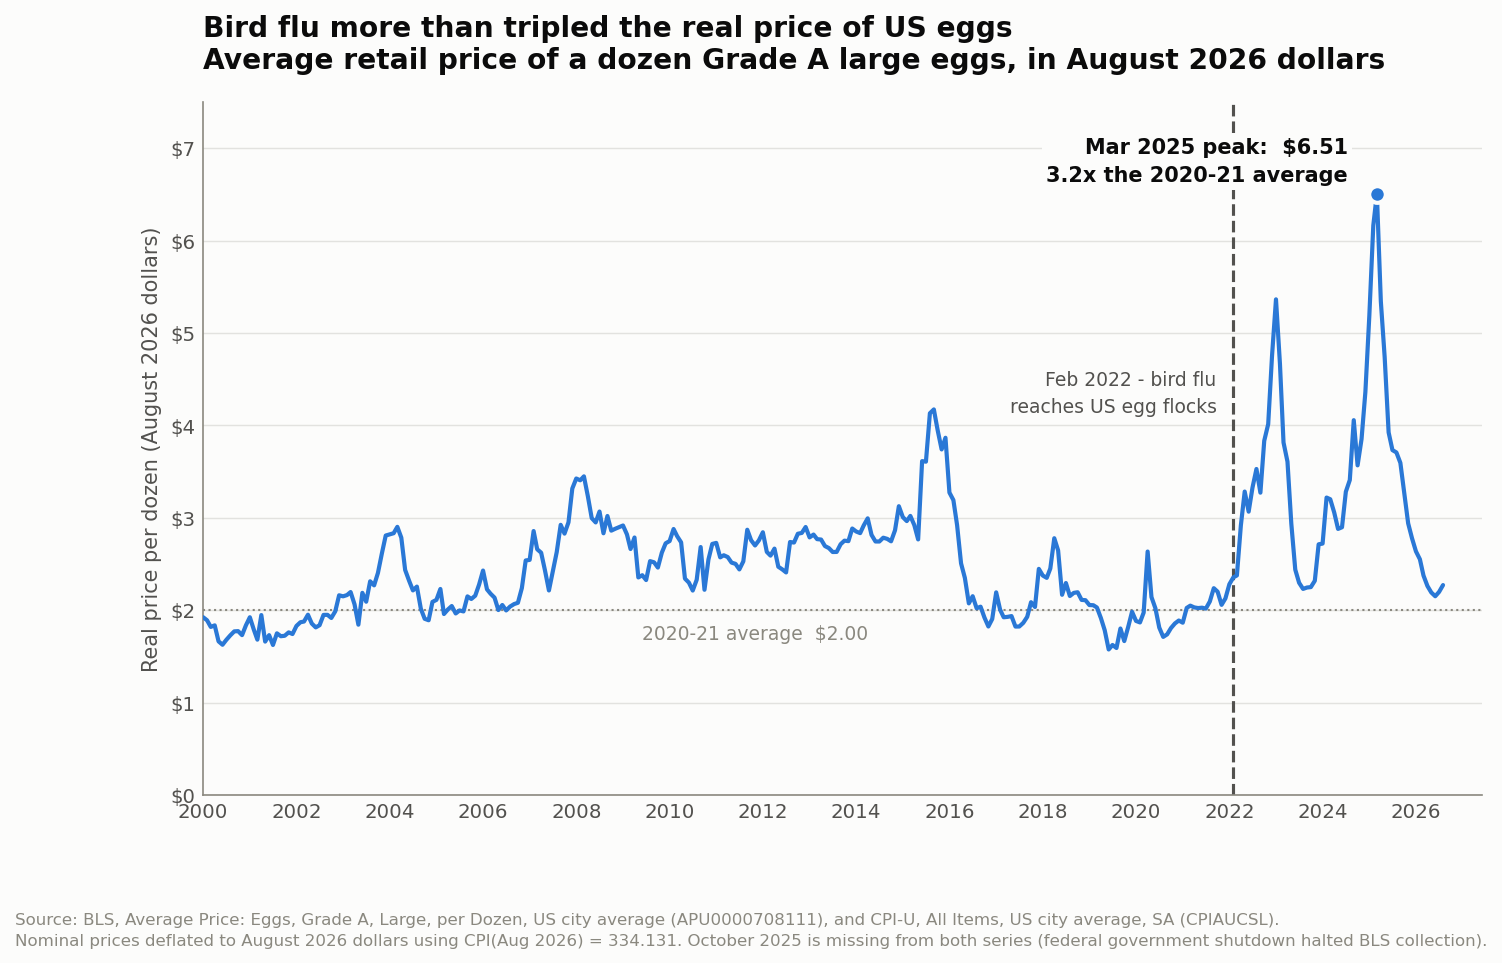

In [11]:
# --- palette (light surface) ---
SURFACE   = "#fcfcfb"
SERIES    = "#2a78d6"   # categorical slot 1
INK       = "#0b0b0b"
INK_SOFT  = "#52514e"
INK_MUTED = "#8a887f"

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# --- the series ---
ax.plot(plot_df.observation_date, plot_df.real_price,
        color=SERIES, lw=2, solid_capstyle="round", zorder=3)

# --- Feb 2022 outbreak line (label sits left of the line, clear of the data) ---
ax.axvline(OUTBREAK, color=INK_SOFT, lw=1.5, ls="--", zorder=2)
ax.annotate("Feb 2022 - bird flu\nreaches US egg flocks",
            xy=(OUTBREAK, 4.35), xytext=(-8, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9, color=INK_SOFT, linespacing=1.5)

# --- 2020-21 baseline (label below the line, in empty space) ---
ax.axhline(P0, color=INK_MUTED, lw=1, ls=":", zorder=2)
ax.annotate(f"2020-21 average  ${P0:,.2f}",
            xy=(pd.Timestamp("2009-06-01"), P0), xytext=(0, -7), textcoords="offset points",
            ha="left", va="top", fontsize=9, color=INK_MUTED)

# --- peak, labeled directly (label upper-left of the marker, above the 2023 spike) ---
ax.plot([PEAK_MONTH], [P_peak], "o", ms=8, color=SERIES,
        mec=SURFACE, mew=2, zorder=4)
ax.annotate(f"{PEAK_MONTH:%b %Y} peak:  ${P_peak:,.2f}\n"
            f"{P_peak / P0:,.1f}x the 2020-21 average",
            xy=(PEAK_MONTH, P_peak), xytext=(-14, 4), textcoords="offset points",
            ha="right", va="bottom", fontsize=10, color=INK, fontweight="semibold",
            linespacing=1.5, zorder=5,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=2))

# --- titles & labels ---
ax.set_title("Bird flu more than tripled the real price of US eggs\n"
             "Average retail price of a dozen Grade A large eggs, in August 2026 dollars",
             loc="left", fontsize=13.5, fontweight="semibold", color=INK, pad=16)
ax.set_ylabel("Real price per dozen (August 2026 dollars)", fontsize=10, color=INK_SOFT)
ax.set_xlabel("")

# --- axes ---
ax.set_xlim(START, pd.Timestamp("2027-06-01"))
ax.set_ylim(0, 7.5)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", color=INK_MUTED, alpha=0.22, lw=0.7)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(INK_MUTED)
    ax.spines[side].set_linewidth(0.8)
ax.tick_params(colors=INK_SOFT, labelsize=9.5, length=0)

# --- source note ---
fig.text(0.011, -0.02,
         "Source: BLS, Average Price: Eggs, Grade A, Large, per Dozen, US city average "
         "(APU0000708111), and CPI-U, All Items, US city average, SA (CPIAUCSL).\n"
         "Nominal prices deflated to August 2026 dollars using CPI(Aug 2026) = "
         f"{CPI_BASE:,.3f}. October 2025 is missing from both series "
         "(federal government shutdown halted BLS collection).",
         ha="left", va="top", fontsize=8, color=INK_MUTED, linespacing=1.5)

PNG = REPO / "real_egg_price_2000_2026.png"
fig.savefig(PNG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
print(f"Saved {PNG.name}")
plt.show()

**Step 2 answers**

| # | Quantity | Value |
|---|---|---|
| 1 | Average real price, 2020–2021 | **$2.00** per dozen |
| 2 | Highest real price, 2000–2026 | **$6.51** per dozen, in **March 2025** |
| 3 | Percent increase, (1) → (2) | **+224.7%** — the real price multiplied by **3.25×** |

All figures in August 2026 dollars. The peak is real, not an inflation artifact: in nominal
terms March 2025 was $6.23, and deflating raises it slightly because the price level has
risen since. The chart is saved as `real_egg_price_2000_2026.png`.

For scale, over the 22 pre-outbreak years (2000 through January 2022) the real price
averaged \$2.37 and never exceeded **\$4.17** — that high came in September 2015, during the
*previous* avian-influenza outbreak. March 2025 cleared that old record by more than half
again, and nine separate months since December 2022 have come in above it.


---
## Step 3 — The own-price elasticity of demand for conventional eggs

From Bakhtavoryan, Hovhannisyan, Devadoss & Lopez (2021), using the text extracted in Step 1.

Report: the number, the table it comes from, and the data and years behind it.

### 3a. Pull the elasticity out of the extracted text

Located by searching `PAPER_TEXT`, so the number comes from the PDF rather than being typed in.

In [12]:
import re

# locate Table 5 and read its "Conventional" row out of the extracted text
t5_start = PAPER_TEXT.index("Table 5. Uncompensated (Marshallian)")
t5_block = PAPER_TEXT[t5_start:t5_start + 1400]

header = re.search(r"Egg\s+(Omega-3\s+Organic\s+Cage-free\s+Conventional\s+Expenditure\s+Income)", t5_block)
row    = re.search(r"Conventional\s+((?:[−-]?[\d.]+\**\s+){6})", t5_block)

print("Table 5 columns :", header.group(1))
print("Conventional row:", " ".join(row.group(1).split()))

# the "Conventional" column is the own-price cell -> 4th of the six numbers
cells = row.group(1).split()
own_price_cell = cells[3]
EPSILON = float(own_price_cell.replace("−", "-").replace("*", ""))

print(f"\nOwn-price cell (Conventional x Conventional): {own_price_cell}")
print(f"EPSILON = {EPSILON}")

Table 5 columns : Omega-3 Organic Cage-free Conventional Expenditure Income
Conventional row: 0.0953*** 0.0417*** 0.0386*** −0.2348*** 0.9516*** 0.0593***

Own-price cell (Conventional x Conventional): −0.2348***
EPSILON = -0.2348


In [13]:
# the standard error sits on the line beneath the estimate
se_line = re.search(r"Conventional\s+(?:[−-]?[\d.]+\**\s+){6}\(([\d.]+)\)\s+\(([\d.]+)\)\s+"
                    r"\(([\d.]+)\)\s+\(([\d.]+)\)", t5_block)
EPSILON_SE = float(se_line.group(4))
print(f"Standard error  = {EPSILON_SE}")
print(f"\nOwn-price elasticity of demand for conventional eggs = "
      f"{EPSILON} (s.e. {EPSILON_SE}), significant at the 1% level")

Standard error  = 0.0023

Own-price elasticity of demand for conventional eggs = -0.2348 (s.e. 0.0023), significant at the 1% level


### 3b. The data and years behind it

In [14]:
data_sent = PAPER_TEXT[PAPER_TEXT.index("We base our empirical analysis"):][:430]
print(" ".join(data_sent.split()))
print()
n_hh = re.search(r"total number of observations \(i.e., households\) of ([\d,]+)", PAPER_TEXT)
print("Households in the sample:", n_hh.group(1))

We base our empirical analysis on the Nielsen Homescan household-level data comprising almost 200 retail markets and spanning a period of January 2014 to December 2016. 11 Nielsen Homescan panels represent the largest household scanner data survey systems nation-wide, which compile information on daily retail food purchases by households for at-home use from a variety of stores (i.e., grocery stores, department stores, conveni

Households in the sample: 159,046


### 3c. Answer

**The number.** The own-price elasticity of demand for **conventional eggs is −0.2348**
(standard error 0.0023, significant at the 1% level). This is the *uncompensated
(Marshallian)* elasticity, evaluated at the sample means.

**The table.** It comes from **Table 5**, *"Uncompensated (Marshallian) own-price, cross-price,
expenditure, and income elasticities of demand from the EASI system"* — the diagonal cell where
the Conventional row meets the Conventional column (p. 294).

**The data and years.** **Nielsen Homescan** household-level scanner data, covering almost
**200 retail markets** and spanning **January 2014 to December 2016**, with **159,046
households**. Accessed through the Kilts Center for Marketing Data Center at the University of
Chicago Booth School of Business. The elasticities are estimated with an Exact Affine Stone
Index (EASI) demand system over four egg types — omega-3, organic, cage-free, and conventional.

**Context from the paper.** Conventional eggs are by far the most inelastic of the four types:

| Egg type | Uncompensated own-price elasticity |
|---|---|
| Organic | −1.0067 |
| Cage-free | −1.0018 |
| Omega-3 | −0.9270 |
| **Conventional** | **−0.2348** |

Conventional eggs are also 84% of total egg expenditures in the sample. The authors note this
is consistent with Heng (2015) and Lusk (2010), and that other studies put egg own-price
elasticities between −0.08 and −0.27.

An elasticity of −0.2348 means a **1% rise in price reduces quantity demanded by only
0.23%** — demand is highly inelastic, which is exactly the condition under which a small supply
shortfall forces a large price move. Step 4 tests whether it is enough to explain the 2025 spike.

*(The paper also reports a compensated (Hicksian) own-price elasticity of −0.1849 for
conventional eggs in Table 6. Step 4 uses the Marshallian figure from Table 5, since that is
the one holding income rather than utility constant — the relevant one for an ordinary market
demand curve.)*

---
## Step 4 — Would that elasticity predict the price we actually saw?

**The setup.** Assume 6.3% fewer eggs were sold in 2025, and the price rose until buyers wanted
only that many. Normal quantity = **1**, so 2025 quantity = **0.937**. The baseline price is
**P₀**, the 2020–21 average from Step 2. Demand is a **straight line** through (P₀, 1), with its
slope set so the elasticity at that point equals the paper's estimate.

**The tool.**

$$\varepsilon = \frac{\%\Delta Q}{\%\Delta P}$$

Three things to find:

- **(a)** By what percent should the price have risen?
- **(b)** What price is that?
- **(c)** What elasticity would make the predicted price equal the actual peak from Step 2?

### 4a. Calibrate the straight-line demand curve

With $Q = a + bP$, elasticity at the point (P₀, 1) is $\varepsilon = b \cdot P_0 / Q_0 = b \cdot P_0$.
So the slope and intercept are pinned down by the elasticity and the baseline price:

$$b = \frac{\varepsilon}{P_0}, \qquad a = 1 - \varepsilon$$

In [15]:
Q_NORMAL = 1.0           # normal quantity, by assumption
PCT_DROP = 6.3           # percent fewer eggs sold in 2025 (USDA flock shortfall)
Q_2025   = Q_NORMAL * (1 - PCT_DROP / 100)

b = EPSILON / P0         # slope of the linear demand curve
a = Q_NORMAL - EPSILON   # intercept

print(f"Baseline price P0          : ${P0:,.4f}")
print(f"Elasticity (Table 5)       : {EPSILON}")
print(f"Quantity, normal           : {Q_NORMAL:.3f}")
print(f"Quantity, 2025 (-{PCT_DROP}%)    : {Q_2025:.3f}")
print()
print(f"Demand curve: Q = {a:,.4f} + ({b:,.5f}) * P")
print(f"  check elasticity at (P0, 1): {b * P0 / Q_NORMAL:,.4f}  (= EPSILON)")

Baseline price P0          : $2.0038
Elasticity (Table 5)       : -0.2348
Quantity, normal           : 1.000
Quantity, 2025 (-6.3%)    : 0.937

Demand curve: Q = 1.2348 + (-0.11718) * P
  check elasticity at (P0, 1): -0.2348  (= EPSILON)


### 4b. (a) By what percent should the price have risen?

Rearranging $\varepsilon = \%\Delta Q / \%\Delta P$ with $\%\Delta Q = -6.3\%$:

$$\%\Delta P = \frac{\%\Delta Q}{\varepsilon} = \frac{-6.3}{\varepsilon}$$

In [16]:
PCT_RISE_PREDICTED = -PCT_DROP / EPSILON

print(f"%change in quantity : {-PCT_DROP:+.1f}%")
print(f"elasticity          : {EPSILON}")
print(f"%change in price    : {-PCT_DROP:+.1f} / {EPSILON} = {PCT_RISE_PREDICTED:+,.2f}%")
print()
print(f"(a) The price should have risen by {PCT_RISE_PREDICTED:,.1f}%.")
print(f"    A {PCT_DROP}% quantity shortfall is amplified "
      f"{PCT_RISE_PREDICTED / PCT_DROP:,.1f}x into the price.")

%change in quantity : -6.3%
elasticity          : -0.2348
%change in price    : -6.3 / -0.2348 = +26.83%

(a) The price should have risen by 26.8%.
    A 6.3% quantity shortfall is amplified 4.3x into the price.


### 4c. (b) What price is that?

In [17]:
P_PREDICTED = P0 * (1 + PCT_RISE_PREDICTED / 100)

# cross-check: read the same price straight off the demand line at Q = 0.937
P_from_line = (Q_2025 - a) / b
assert abs(P_PREDICTED - P_from_line) < 1e-9

print(f"From the percent change : ${P0:,.4f} x (1 + {PCT_RISE_PREDICTED/100:,.4f}) = ${P_PREDICTED:,.4f}")
print(f"From the demand line    : ({Q_2025:.3f} - {a:,.4f}) / ({b:,.5f})  = ${P_from_line:,.4f}")
print("  the two agree\n")
print(f"(b) Predicted price: ${P_PREDICTED:,.2f} per dozen (August 2026 dollars)")
print(f"    Actual peak    : ${P_peak:,.2f} in {PEAK_MONTH:%B %Y}")
print(f"    Shortfall      : the model misses the actual peak by ${P_peak - P_PREDICTED:,.2f}, "
      f"or {P_peak / P_PREDICTED:,.1f}x")

From the percent change : $2.0038 x (1 + 0.2683) = $2.5415
From the demand line    : (0.937 - 1.2348) / (-0.11718)  = $2.5415
  the two agree

(b) Predicted price: $2.54 per dozen (August 2026 dollars)
    Actual peak    : $6.51 in March 2025
    Shortfall      : the model misses the actual peak by $3.96, or 2.6x


### 4d. (c) What elasticity would reproduce the actual peak?

Run the same formula backwards, using the actual percent increase from Step 2:

$$\varepsilon_{\text{implied}} = \frac{\%\Delta Q}{\%\Delta P_{\text{actual}}} = \frac{-6.3}{224.7}$$

In [18]:
EPSILON_IMPLIED = -PCT_DROP / PCT_INCREASE

print(f"actual %change in price : {PCT_INCREASE:+,.2f}%   (${P0:,.2f} -> ${P_peak:,.2f})")
print(f"assumed %change in qty  : {-PCT_DROP:+.1f}%")
print(f"implied elasticity      : {-PCT_DROP:+.1f} / {PCT_INCREASE:,.2f} = {EPSILON_IMPLIED:,.5f}")
print()
print(f"(c) It would take an elasticity of {EPSILON_IMPLIED:,.3f} to explain the actual peak,")
print(f"    versus the paper's {EPSILON}. That is {EPSILON / EPSILON_IMPLIED:,.1f}x more inelastic.")
print(f"    At {EPSILON_IMPLIED:,.3f}, a 1% price rise would cut quantity demanded by only "
      f"{abs(EPSILON_IMPLIED):,.3f}%.")

actual %change in price : +224.69%   ($2.00 -> $6.51)
assumed %change in qty  : -6.3%
implied elasticity      : -6.3 / 224.69 = -0.02804

(c) It would take an elasticity of -0.028 to explain the actual peak,
    versus the paper's -0.2348. That is 8.4x more inelastic.
    At -0.028, a 1% price rise would cut quantity demanded by only 0.028%.


### 4e. Everything together

In [19]:
summary = pd.DataFrame({
    "Quantity": [
        "Baseline price, 2020-21 average (P0)",
        "Assumed quantity change in 2025",
        "Own-price elasticity, Table 5 (conventional eggs)",
        "(a) Predicted price rise",
        "(b) Predicted price",
        "Actual peak real price (Mar 2025)",
        "Actual price rise",
        "(c) Elasticity implied by the actual peak",
    ],
    "Value": [
        f"${P0:,.2f}",
        f"{-PCT_DROP:+.1f}%",
        f"{EPSILON}",
        f"{PCT_RISE_PREDICTED:+,.1f}%",
        f"${P_PREDICTED:,.2f}",
        f"${P_peak:,.2f}",
        f"{PCT_INCREASE:+,.1f}%",
        f"{EPSILON_IMPLIED:,.3f}",
    ],
})
print(summary.to_string(index=False))

                                         Quantity   Value
             Baseline price, 2020-21 average (P0)   $2.00
                  Assumed quantity change in 2025   -6.3%
Own-price elasticity, Table 5 (conventional eggs) -0.2348
                         (a) Predicted price rise  +26.8%
                              (b) Predicted price   $2.54
                Actual peak real price (Mar 2025)   $6.51
                                Actual price rise +224.7%
        (c) Elasticity implied by the actual peak  -0.028


---
## Findings

**Why would a small drop in supply cause such a big jump in price?**

**Because demand for conventional eggs is extremely inelastic.** When people barely cut back
as the price climbs, the price has to move a long way before buyers willingly accept a smaller
quantity. The paper's estimate of −0.2348 means a 1% price rise trims purchases by just 0.23%,
so clearing a 6.3% shortfall takes a price rise roughly four times larger than the shortfall
itself: **+26.8%**, carrying the price from \$2.00 to **\$2.54**. Inelastic demand is a genuine
amplifier, and that is the core mechanism behind the question.

**But that amplifier alone does not get us to what actually happened.** The real price peaked at
**\$6.51** in March 2025 — **+224.7%**, about **2.6×** the predicted \$2.54 and \$3.96 above it.
Running the formula backwards, matching the actual peak would require an elasticity of
**−0.028**, roughly **8× more inelastic** than the paper's estimate — a market where a 1% price
rise cuts purchases by only three-hundredths of a percent. That is an implausibly extreme value,
which is informative: it says the simple exercise is leaving something out rather than that
demand truly collapsed to near-vertical.

**What the numbers do and don't establish.** The comparison is internally consistent — the two
routes to the predicted price agree exactly, and the direction is right. What it shows is that
inelastic demand explains the *shape* of the answer (a small quantity shock producing a much
larger price move) but only part of its *size*. The gap between \$2.54 and \$6.51 is the part this
model does not account for.

**Caveats, stated plainly.**

- The 6.3% is a USDA **flock-size** figure, used here as the quantity-sold shock because the
  assignment specifies it. Flock size and eggs actually sold are not the same thing, and the
  true quantity shock in any given month could be larger or smaller.
- The demand curve is a **straight line calibrated at the 2020–21 point**. It is a local
  approximation, and a 225% price move is far outside the range where that approximation is
  reliable.
- The elasticity comes from **2014–2016 Nielsen Homescan** data — a normal market, years before
  the outbreak. There is no reason it must still hold during a shortage.
- This compares a **2020–21 average** to a **single-month peak**, which overstates the jump
  relative to comparing like with like.
- Nothing here uses supply-side data, so the exercise cannot speak to anything outside the
  demand curve.
